In [3]:
!pip install myqlm -q -q

In [2]:
# Lire cette cellule, puis l'exécuter sans modification.
import numpy as np
from qat.lang import QRoutine, H, CNOT, RY, Z, X, Program
from qat.qpus import get_default_qpu

qpu = get_default_qpu()

def display_result(circuit, nbshots=0, idx=None):
  '''
  Utilitary function to provide a nice display of the circuits.
  '''
  result = qpu.submit(circuit.to_job(nbshots=nbshots, qubits=idx)) # Objet de la classe Result
  if nbshots:
      tmp = {}
      for sample in result:
          state = sample.state
          if not state in tmp:
              tmp[state] = 0.
          tmp[sample.state] += sample.probability
      for state, proba in tmp.items():
          print(f"État {state}: probabilité {proba:.3f}")
  else:
      for sample in result:
          print(f"État {sample.state}: probabilité {sample.probability:.3f}, amplitude {sample.amplitude:.3f}")


### Introduction

Supposons que l'on dispose d'un *oracle*, c'est-à-dire un opérateur quantique agissant comme une boîte noire, au contenu inconnu, qui contient l'information d'une fonction $f: X=\{ 0, 1 \}^n \rightarrow \{0, 1\}$. On suppose que $f$ est soit *constante*, soit *équilibrée*, au sens suivant:
- constante: $\text{Card}f(X) = 1$
- équilibrée:  $\text{Card}f^{-1}(\{0\}) = \text{Card}f^{-1}(\{0\}) = 2^{n-1}$.

Autrement dit, soit $f$ ne prend qu'une valeur, soit elle prend chacune des 2 valeurs 0 et 1 sur exactement la moitié de ses entrées.
Notre objectif est de déterminer si $f$ est constante ou équilibrée.

**Question 1.** Classiquement, combien de fois faut-il évaluer $f$ au pire des cas pour établier si elle est constante ou équilibrée ?

Quantiquement, le problème peut être résolu avec un seul appel à l'implémentation de $f$, grâce à l'[algorithme de Deutsch-Jozsa](https://fr.wikipedia.org/wiki/Algorithme_de_Deutsch-Jozsa). Cet algorithme repose sur l'application de l'oracle encodant $f$ à l'état superposé de toutes les entrées classiques possibles.

### Algorithme de Deutsch-Jozsa, $n=1$

Dans cette partie, on suppose que $n=1$. Le problème revient à tester si $f(0) = f(1)$ ou non.

**Question 2.** Lire le circuit quantique représenté sur [cette page](https://fr.wikipedia.org/wiki/Algorithme_de_Deutsch-Jozsa#/media/Fichier:Deutsch-Jozsa_Algorithm.svg) en considérant que l'oracle $U_f$ agit selon
$$
  U_f (\vert x \rangle \otimes \vert y \rangle)
  =
  \vert x \rangle \otimes  \vert y \oplus f(x) \rangle.
$$
Vérifier que la mesure du qubit du haut permet de déterminer si $f$ est constante ou équilibrée.

**Question 3.**
Que vaut $U_f^2$ ? Commenter.

**Question 4.** Implémenter l'oracle pour le cas constant et le tester.

In [ ]:
def constant_oracle():
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

In [ ]:
# Test for x = 0
rout = constant_oracle()  # Called directly: the registers are initialized to 0
display_result(rout)

# Test for x = 1
rout = QRoutine()  # New routine
qubits = rout.new_wires(2)
X(qubits[0])  # x = 1
constant_oracle()(qubits)
display_result(rout)

**Question 5.** Implémenter l'oracle pour le cas équilibré et le tester.

In [ ]:
def balanced_oracle():
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

In [ ]:
# Test for x = 0
rout = balanced_oracle()  # Called directly: the registers are initialized to 0
display_result(rout)

# Test for x = 1
rout = QRoutine()  # New routine
qubits = rout.new_wires(2)
X(qubits[0])  # x = 1
balanced_oracle()(qubits)
display_result(rout)

**Question 6.** Implémenter le circuit vu précédemment.

In [ ]:
def deutsch_jozsa_1(oracle):
    # Program creation
    prog = Program()

    # Allocation of two qubits and one classical bit
    qubits = prog.qalloc(2)
    bits = prog.calloc(1)

    # <<< COMPLETE HERE >>>

    # Final measurement
    prog.measure(qubits[0], bits)

    return prog

In [ ]:
# Test with the constant oracle (expected result: 0)
constant_circuit = deutsch_jozsa_1(constant_oracle()).to_circ()
display_result(constant_circuit, nbshots=1000, idx=[0])

# Test with the balanced oracle (expected result: 1)
balanced_circuit = deutsch_jozsa_1(balanced_oracle()).to_circ()
display_result(balanced_circuit, nbshots=1000, idx=[0])

### Algorithme de Deutsch-Jozsa, $n \ge 1$

L'algorithme se généralise directement en créant la superposition de tous les entiers de 0 à $2^n-1$.

**Question 7.** Vérifier que cette superposition est obtenue en appliquant une porte de Hadamard sur chacun des $n$ premiers qubits.

In [ ]:
n = 3
rout = QRoutine()

# <<< COMPLETE HERE >>>

display_result(rout)

**Question 8.** Implémenter le circuit pour un nombre arbitraire de qubits.

###

In [ ]:
def deutsch_jozsa(n, oracle):
    # Program creation
    prog = Program()

    # <<< COMPLETE HERE >>>

    return prog

**Question 9.** Implémenter le circuit présenté sur l'image suivante, à partir de portes CNOT et CCNOT (aussi dites Toffoli), afin de l'utiliser comme oracle.


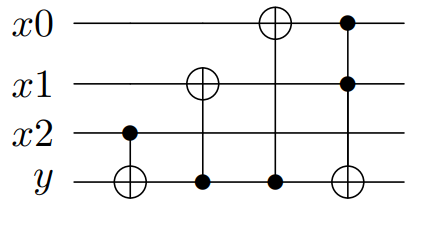

In [ ]:
def oracle():
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

**Question 10.** Vérifier, pour tous les $x = x_0x_1x_2$ en entrée, si cet oracle imlémente une fonction $f(x) = y$ constante ou équilibrée.

In [ ]:
# <<< COMPLETE HERE >>>

En appliquant l'algorithme de Deutsch-Jozsa à cet oracle, on obtient une probabilité nulle de mesurer $\vert 000 \rangle$ : la fonction est bien équilibrée.

In [ ]:
circuit = deutsch_jozsa(n, oracle()).to_circ()
display_result(circuit, nbshots=1000, idx=[0,1,2])

### Algorithme de Bernstein-Vazirani


L'[algorithme de Bernstein-Vazirani](https://fr.wikipedia.org/wiki/Algorithme_de_Bernstein-Vazirani) est une variante de l'algorithme de Deutsch-Jozsa. L'objectif est de retrouver une chaîne de bits secrète encodée dans une fonction $f$.
Précisément, soit $s \in \{0,1\}^n$ une chaîne de bits secrète et $O_f$ un oracle implémentant
$$
f(x) = x \cdot s \mod 2 = x_0 s_0 \oplus x_1 s_1 \oplus \cdots \oplus x_{n-1} s_{n-1}.
$$
**Objectif :** retrouver $s$.

**Question 11.** Justifier que classiquement, $n$ évaluations de $f$ suffisent à résoudre le problème.

Quantiquement, comme pour Deutsch-Jozsa, une seule requête à l'oracle évalue $f$ sur toutes les bitstrings.

**Question 12.** Implémenter l'oracle qui prend $s = s_0 \dots s_{n-1}$ en entrée. Pour ce faire, appliquer une porte CNOT entre le qubit d'entrée $x_i$ et le qubit de sortie $y$ si $s_i = 1$, et ne rien faire si $s_i=0$.



In [ ]:
def bernstein_vazirani_oracle(s):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

**Question 13.** Appliquer l'algorithme de Deutsch-Jozsa à cet oracle et vérifier que $s$ est bien obtensible par cette méthode.

In [ ]:
n = 4
s = [1, 1, 0, 1]

# <<< COMPLETE HERE >>>